<a href="https://colab.research.google.com/github/zeyneppbaran/ml-proje/blob/main/notebooks/05_dengeleme_smote.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 - Sınıf Dengesizliği ve SMOTE

**Sorumlu:** Kişi 5 (ad soyad yazılacak)

**Ödevdeki karşılığı:** 3. Veri Analizi (dengesizlik ve dengeleme)

In [ ]:
# KURULUM: bu hucreyi her oturumun basinda bir kez calistir.
# Repoyu Colab'e indirir; boylece src/ortak.py kullanilabilir.
import os
REPO_URL = "https://github.com/zeyneppbaran/ml-proje.git"  # TODO: kendi repo adresiniz
if not os.path.exists("/content/ml-proje"):
    !git clone {REPO_URL} /content/ml-proje
else:
    !git -C /content/ml-proje pull
%cd /content/ml-proje

Cloning into '/content/ml-proje'...
remote: Enumerating objects: 155, done.
remote: Counting objects: 100% (155/155), done.
remote: Compressing objects: 100% (138/138), done.
remote: Total 155 (delta 90), reused 31 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (155/155), 1.15 MiB | 7.43 MiB/s, done.
Resolving deltas: 100% (90/90), done.
/content/ml-proje


In [ ]:
import os
import sys
import pandas as pd

# Çalışma dizini 'notebooks/' ise bir üst dizine (repo köküne) geç
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

from src.ortak import veri_yukle, veriyi_bol, on_isleyici, degerlendir

# 1. Veriyi yükle
df = veri_yukle("data/bank-additional-full.csv")
print("Veri boyutu:", df.shape)

# 2. %80 Eğitim / %20 Test böl (src/ortak.py içinde random_state=42 ve stratify=y tanımlı)
X_train_raw, X_test_raw, y_train, y_test = veriyi_bol(df)

# 3. Ortak ön işleyiciyi yalnızca eğitim verisine fit et
preprocessor = on_isleyici()
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

sutun_isimleri = preprocessor.get_feature_names_out()
X_train = pd.DataFrame(X_train, columns=sutun_isimleri, index=X_train_raw.index)
X_test = pd.DataFrame(X_test, columns=sutun_isimleri, index=X_test_raw.index)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Veri boyutu: (41188, 22)
X_train: (32950, 58) | X_test: (8238, 58)


## C7b. SMOTE uygulaması (sadece eğitim verisine)

SMOTE Öncesi Sınıf Dağılımı:
 y
0    29238
1     3712
Name: count, dtype: int64

SMOTE Sonrası Sınıf Dağılımı:
 y
0    29238
1    29238
Name: count, dtype: int64


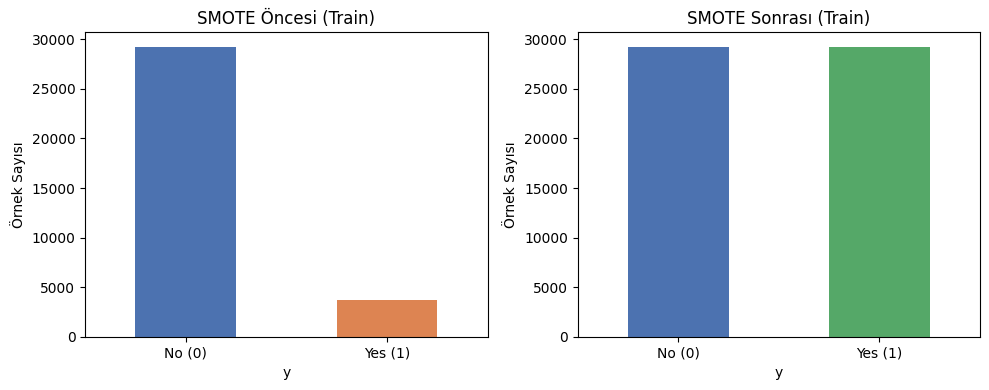

In [ ]:
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

smote_ornek = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote_ornek.fit_resample(X_train, y_train)

print("SMOTE Öncesi Sınıf Dağılımı:\n", y_train.value_counts())
print("\nSMOTE Sonrası Sınıf Dağılımı:\n", y_train_smote.value_counts())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], title="SMOTE Öncesi (Train)")
y_train_smote.value_counts().plot(kind="bar", ax=axes[1], color=["#4C72B0", "#55A868"], title="SMOTE Sonrası (Train)")
for ax in axes:
    ax.set_xticklabels(["No (0)", "Yes (1)"], rotation=0)
    ax.set_ylabel("Örnek Sayısı")
plt.tight_layout()
plt.savefig("figures/smote_sinif_dagilimi.png", dpi=300, bbox_inches="tight")
plt.show()